In [2]:
import requests
import json
import matplotlib.pyplot as plt

In [3]:
# 동영상 ID
video_id = "RwWx5pKS3eA"

get url!!!
get url finished!!!!!


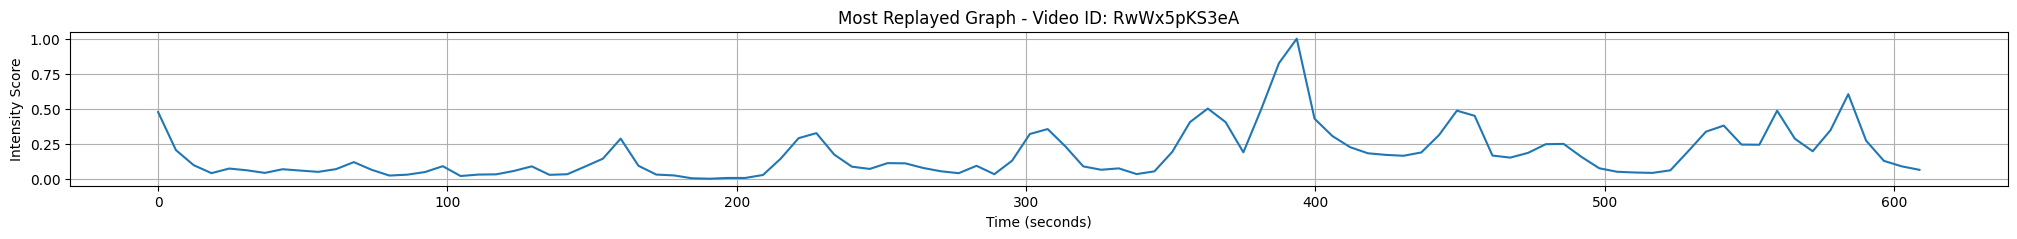

In [4]:



# API 엔드포인트 URL
url = f"https://yt.lemnoslife.com/videos?part=mostReplayed&id={video_id}"

# API 호출하여 JSON 데이터 가져오기
print('get url!!!')
response = requests.get(url)
print('get url finished!!!!!')
data = response.json()

# markers 리스트에서 startMillis와 intensityScoreNormalized 값 추출
markers = data['items'][0]['mostReplayed']['markers']
start_millis = [marker['startMillis'] for marker in markers]
intensity_scores = [marker['intensityScoreNormalized'] for marker in markers]

# 밀리초를 초로 변환
start_seconds = [millis / 1000 for millis in start_millis]

# 그래프 그리기
plt.figure(figsize=(25, 2))
plt.plot(start_seconds, intensity_scores)
plt.title(f'Most Replayed Graph - Video ID: {video_id}')
plt.xlabel('Time (seconds)')
plt.ylabel('Intensity Score')
plt.grid(True)
plt.show()


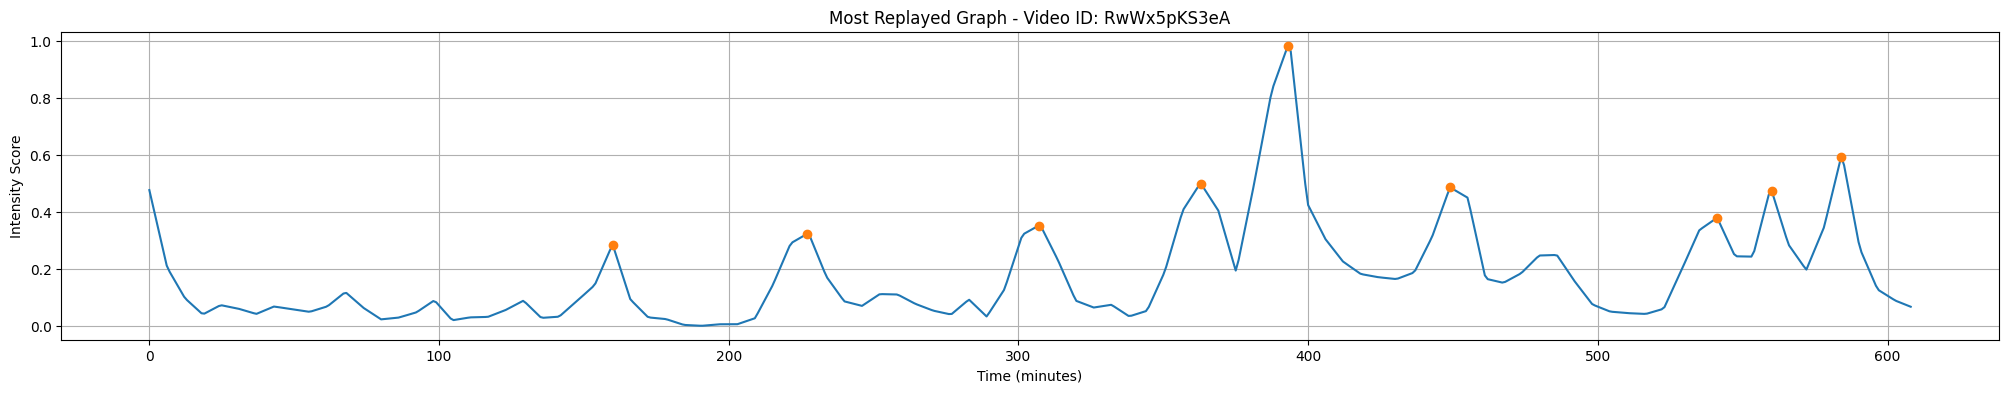

In [5]:
# 보간 함수 생성
from scipy.interpolate import interp1d
import numpy as np
from scipy.signal import find_peaks

interpolation_function = interp1d(start_seconds, intensity_scores, kind='linear', fill_value="extrapolate")

# 1초 간격으로 새로운 시간 생성
total_duration_seconds = start_seconds[-1]
new_time = np.arange(0, total_duration_seconds, 1)

# 새로운 시간에 대한 보간된 값 계산
smoothed_intensity_scores = interpolation_function(new_time)
peaks, _ = find_peaks(smoothed_intensity_scores, prominence = 0.1)

# 그래프 그리기
plt.figure(figsize=(25, 4))
plt.plot(new_time, smoothed_intensity_scores)  # 분으로 변환하여 표시
plt.plot(new_time[peaks], smoothed_intensity_scores[peaks], "o", label='Peaks')

plt.title(f'Most Replayed Graph - Video ID: {video_id}')
plt.xlabel('Time (minutes)')
plt.ylabel('Intensity Score')
plt.grid(True)
plt.show()

In [6]:
rewards_lst = smoothed_intensity_scores

In [7]:
class State:
    def __init__(self, peak_int, count, time, rewards_lst= rewards_lst, peaks = peaks):
        self.peak = peak_int
        self.frame = -1
        self.count = count
        self.time = time
        self.reward = rewards_lst[time]
        self.next_states = []

    def get_info(self):
        # info = f'Peak: {self.peak}, Frame: {self.frame}, Count: {self.count}, Reward: {self.reward}, Time: {self.time}, Next State {self.next_states}'
        info = f'Peak: {self.peak}, Count: {self.count},  Next State {self.next_states}'
        return info




In [8]:
# count_durations = []  # 각 피크마다 count_duration을 계산해서 저장

# 각 피크마다 count_duration 계산
# for i, peak in enumerate(peaks):
#     if i < len(peaks) - 1:
#         count_duration = min(50, peaks[i + 1] - peak)
#     else:
#         count_duration = min(50, len(smoothed_intensity_scores) - peak)
#     count_durations.append(count_duration)

In [9]:
states = []
# count_duration = 20 ### 제한 시간
total_length = len(smoothed_intensity_scores)
for i, peak in enumerate(peaks, start=1):
    for j in range(total_length - peak):
        temp = peak + j
        reward = smoothed_intensity_scores[temp]
        time = temp
        state = State(peak_int=i, count=j, time = time )
        states.append(state)

In [10]:
for state in states:
    print(state.get_info())


Peak: 1, Count: 0,  Next State []
Peak: 1, Count: 1,  Next State []
Peak: 1, Count: 2,  Next State []
Peak: 1, Count: 3,  Next State []
Peak: 1, Count: 4,  Next State []
Peak: 1, Count: 5,  Next State []
Peak: 1, Count: 6,  Next State []
Peak: 1, Count: 7,  Next State []
Peak: 1, Count: 8,  Next State []
Peak: 1, Count: 9,  Next State []
Peak: 1, Count: 10,  Next State []
Peak: 1, Count: 11,  Next State []
Peak: 1, Count: 12,  Next State []
Peak: 1, Count: 13,  Next State []
Peak: 1, Count: 14,  Next State []
Peak: 1, Count: 15,  Next State []
Peak: 1, Count: 16,  Next State []
Peak: 1, Count: 17,  Next State []
Peak: 1, Count: 18,  Next State []
Peak: 1, Count: 19,  Next State []
Peak: 1, Count: 20,  Next State []
Peak: 1, Count: 21,  Next State []
Peak: 1, Count: 22,  Next State []
Peak: 1, Count: 23,  Next State []
Peak: 1, Count: 24,  Next State []
Peak: 1, Count: 25,  Next State []
Peak: 1, Count: 26,  Next State []
Peak: 1, Count: 27,  Next State []
Peak: 1, Count: 28,  Next Stat

In [25]:
# 다음 상태 정의 함수
import pdb
def fill_next_states(states, min_duration):
    for state in states:
        next_states = []
        
        for next_state in states:
            
            # 같은 피크 내에서 다음 상태로 전이, 같은 피크 내에서는 1개씩만. 
            if (next_state.peak == state.peak) and (next_state.count == state.count + 1):
                next_states.append(next_state)

            # 다음 피크를 선택할 때에는 
            # 진행중인 state가 2초 이상이고,                피크이고                    현재 지속 시간보다 
            if  (state.count >= min_duration) and (next_state.count == 0) and (state.time < next_state.time):
                next_states.append(next_state)
        # print("=======")
        
        state.next_states = next_states
        # print(state.next_states)

fill_next_states(states, min_duration=2)


In [26]:
peaks

array([160, 227, 307, 363, 393, 449, 541, 560, 584], dtype=int64)

In [27]:
for state in states:
    if state.time == 500:
        print(state.get_info())


Peak: 1, Count: 340,  Next State [<__main__.State object at 0x0000015C3D4B9570>, <__main__.State object at 0x0000015C3D525C30>, <__main__.State object at 0x0000015C3D5268F0>, <__main__.State object at 0x0000015C3D527220>]
Peak: 2, Count: 273,  Next State [<__main__.State object at 0x0000015C3D4D1D50>, <__main__.State object at 0x0000015C3D525C30>, <__main__.State object at 0x0000015C3D5268F0>, <__main__.State object at 0x0000015C3D527220>]
Peak: 3, Count: 193,  Next State [<__main__.State object at 0x0000015C3D4ED630>, <__main__.State object at 0x0000015C3D525C30>, <__main__.State object at 0x0000015C3D5268F0>, <__main__.State object at 0x0000015C3D527220>]
Peak: 4, Count: 137,  Next State [<__main__.State object at 0x0000015C3D508490>, <__main__.State object at 0x0000015C3D525C30>, <__main__.State object at 0x0000015C3D5268F0>, <__main__.State object at 0x0000015C3D527220>]
Peak: 5, Count: 107,  Next State [<__main__.State object at 0x0000015C3D50A9B0>, <__main__.State object at 0x000

In [28]:
def find_highlights(states, F):
    dp = np.zeros((len(states), F+1))
    path = [[None for _ in range(F+1)] for _ in range(len(states))]

    for f in range(1, F+1):
        for i, state in enumerate(states):
            if state.count == 0:
                # print(" here ")
                # print(state.get_info())
                dp[i][f] = state.reward
                path[i][f] = i
            else:
                max_prev_reward = -float('inf')
                best_prev_state = None
                for prev_state in state.next_states:
                    prev_idx = states.index(prev_state)
                    # df [i+1][f]
                    if dp[prev_idx][f-1] + state.reward > max_prev_reward:
                        max_prev_reward = dp[prev_idx][f-1] + state.reward
                        best_prev_state = prev_idx
                if best_prev_state is not None:
                    dp[i][f] = max_prev_reward
                    path[i][f] = best_prev_state

    highlights = []
    highlights_peaks = []
    state_idx = np.argmax(dp[:, -1])
    f = F
    while f > 0 and state_idx is not None:
        highlights.append(states[state_idx].time)
        state_idx = path[state_idx][f]
        print(states[state_idx].peak, states[state_idx].count)
        if states[state_idx].count == 0:
            print("hello")
            highlights_peaks.append(states[state_idx].time)
        f -= 1

    return highlights, highlights_peaks

# 예시 데이터
peaks = peaks
smoothed_intensity_scores = smoothed_intensity_scores
F = 200


highlights, highlights_peaks= find_highlights(states, F)



1 194
1 195
1 196
1 197
1 198
1 199
1 200
1 201
1 202
1 203
1 204
1 205
1 206
1 207
1 208
1 209
1 210
1 211
1 212
1 213
1 214
1 215
1 216
1 217
1 218
1 219
1 220
1 221
1 222
1 223
1 224
1 225
1 226
1 227
1 228
1 229
1 230
1 231
1 232
1 233
1 234
1 235
1 236
1 237
1 238
1 239
1 240
1 241
1 242
1 243
1 244
1 245
1 246
1 247
1 248
1 249
1 250
1 251
1 252
1 253
1 254
1 255
1 256
1 257
1 258
1 259
1 260
1 261
1 262
1 263
1 264
1 265
1 266
1 267
1 268
1 269
1 270
1 271
1 272
1 273
1 274
1 275
1 276
1 277
1 278
1 279
1 280
1 281
1 282
1 283
1 284
1 285
1 286
1 287
1 288
1 289
1 290
1 291
1 292
1 293
1 294
1 295
1 296
1 297
1 298
1 299
1 300
1 301
1 302
1 303
1 304
1 305
1 306
1 307
1 308
1 309
1 310
1 311
1 312
1 313
1 314
1 315
1 316
1 317
1 318
1 319
1 320
1 321
1 322
1 323
1 324
1 325
1 326
1 327
1 328
1 329
1 330
1 331
1 332
1 333
1 334
1 335
1 336
1 337
1 338
1 339
1 340
1 341
1 342
1 343
1 344
1 345
1 346
1 347
1 348
1 349
1 350
1 351
1 352
1 353
1 354
1 355
1 356
1 357
1 358
1 359
1 36

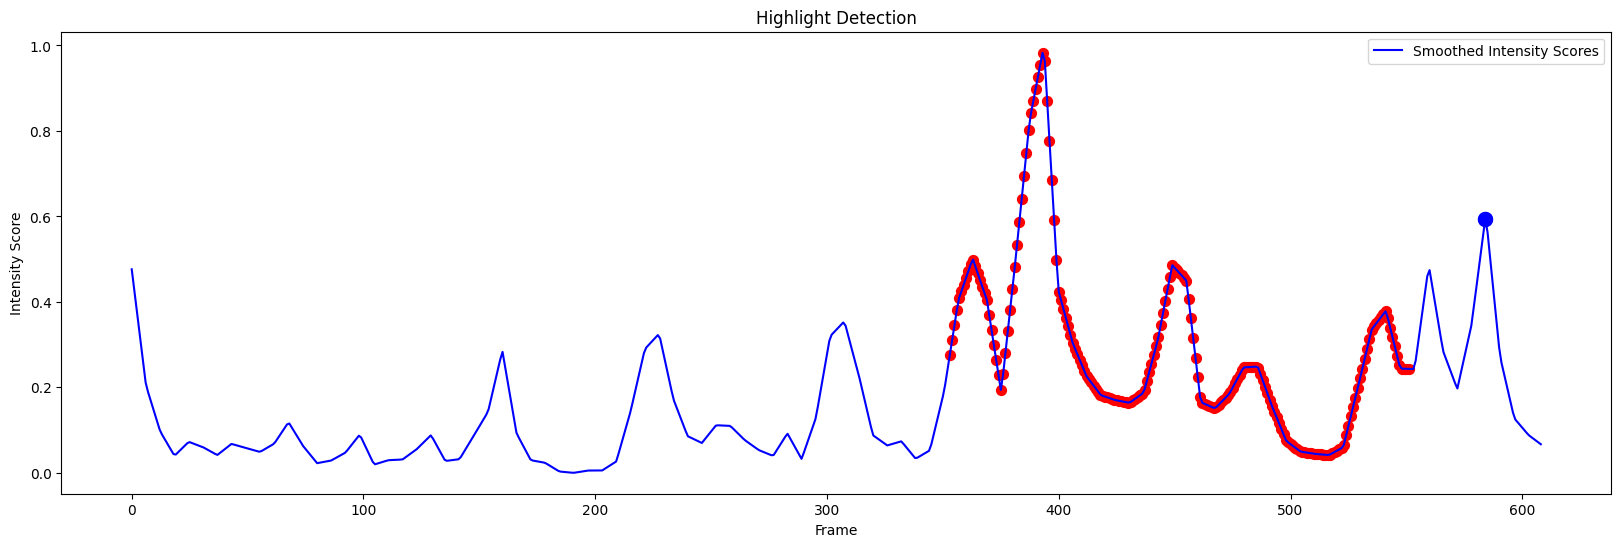

In [24]:
# 그래프 그리기
plt.figure(figsize=(20, 6))
plt.plot(smoothed_intensity_scores, 'b-', label='Smoothed Intensity Scores')
for point in highlights:
    plt.scatter(point, smoothed_intensity_scores[point], color='red', s=50)  # s는 점의 크기

for point in highlights_peaks:
    plt.scatter(point, smoothed_intensity_scores[point], color='blue', s=100)  # s는 점의 크기
plt.xlabel('Frame')
plt.ylabel('Intensity Score')
plt.title('Highlight Detection')
plt.legend()
plt.show()

# 앞뒤로 해보기

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# 상태 클래스 정의
class State:
    def __init__(self, peak, start, end, reward):
        self.peak = peak
        self.start = start
        self.end = end
        self.reward = reward
        self.duration = end - start

    def __repr__(self):
        return f'State(Peak: {self.peak}, Start: {self.start}, End: {self.end}, Reward: {self.reward}, Duration: {self.duration})'

states = []
max_duration = len(sm)  # 각 구간의 최대 길이

# 상태 생성
for peak in peaks:
    for length in range(1, max_duration + 1):
        start = max(0, peak - length // 2)
        end = min(len(smoothed_intensity_scores), peak + length // 2)
        reward = np.sum(smoothed_intensity_scores[start:end])
        state = State(peak=peak, start=start, end=end, reward=reward)
        states.append(state)

def fill_next_states(states, min_duration = 2):
    for state in states:
        next_states = []
        for next_state in states:
            if next_state.start > state.end and state.duration >= min_duration:
                next_states.append(next_state)
        state.next_states = next_states

fill_next_states(states, min_duration = 5)





In [29]:
def find_highlights(states, F):
    max_length = int(F)
    dp = np.zeros((len(states), max_length + 1))
    path = [[None for _ in range(max_length + 1)] for _ in range(len(states))]

    for f in range(1, max_length + 1):
        for i, state in enumerate(states):
            if state.duration <= f:
                dp[i][f] = state.reward
                path[i][f] = i
                for prev_state in state.next_states:
                    prev_idx = states.index(prev_state)
                    remaining_time = f - state.duration
                    if dp[prev_idx][remaining_time] + state.reward > dp[i][f]:
                        dp[i][f] = dp[prev_idx][remaining_time] + state.reward
                        path[i][f] = prev_idx

    highlights = []
    state_idx = np.argmax(dp[:, -1])
    f = max_length
    while f > 0 and state_idx is not None:
        highlights.append((states[state_idx].start, states[state_idx].end))
        prev_idx = path[state_idx][f]
        f -= states[state_idx].duration
        state_idx = prev_idx
    highlights.reverse()

    return highlights

# 예시 데이터로 실행
F = 10  # 총 길이 30초로 설정
highlights = find_highlights(states, F)

print("Highlights:", highlights)



AttributeError: 'State' object has no attribute 'duration'

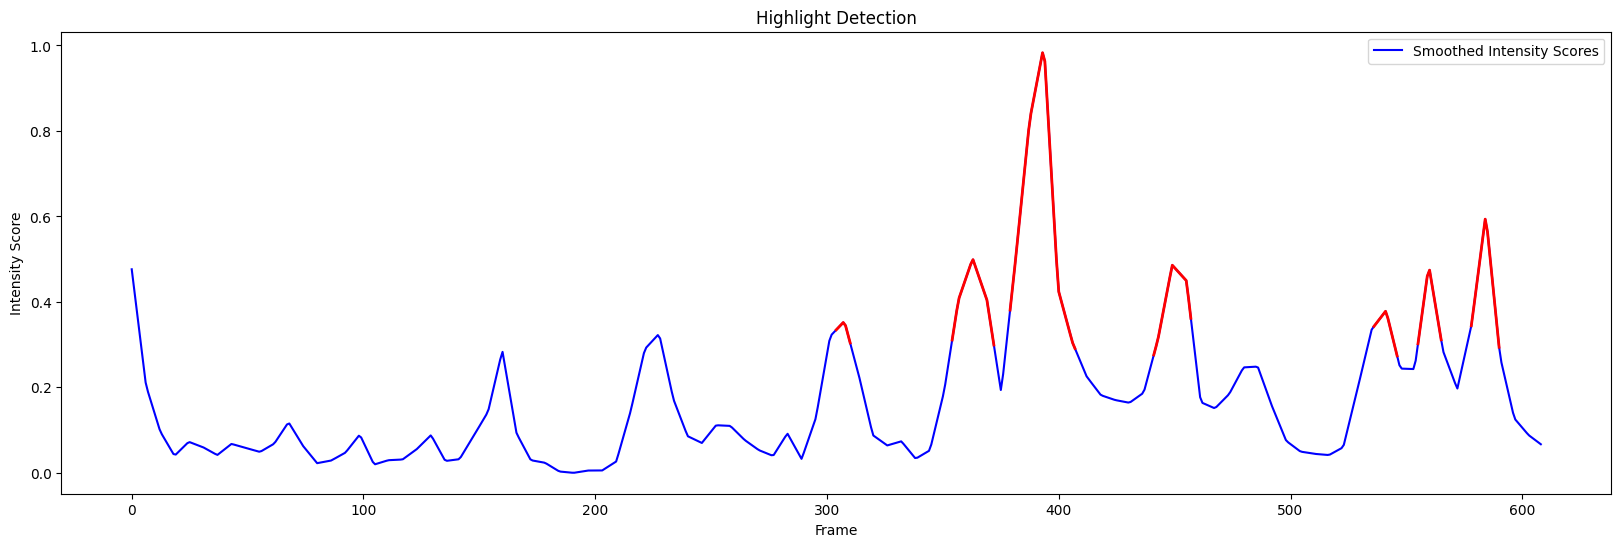

In [ ]:
# 예시 데이터 (peaks와 rewards 사용)
x = np.arange(0, len(smoothed_intensity_scores))
y = smoothed_intensity_scores
plt.figure(figsize=(20, 6))
plt.plot(x, y, 'b-', label='Smoothed Intensity Scores')

# 최적 경로를 빨간색으로 시각화
for start, end in highlights:
    plt.plot(range(start, end+1), smoothed_intensity_scores[start:end+1], 'r-', linewidth=2)

plt.xlabel('Frame')
plt.ylabel('Intensity Score')
plt.title('Highlight Detection')
plt.legend()
plt.show()
